# Hipóteses — o mundo canta cada vez mais na própria língua, mas sobre as mesmas coisas?

Top 100 anual do Spotify de 9 países (EUA, Reino Unido, Canadá, Austrália, Alemanha, França, Brasil, México, Japão),
2017–2025. Entradas: `finalData.csv` (via `comum.carrega_top`) e as saídas do `pipelineGPU.ipynb` em `dados/`.

| Hipótese | Enunciado | Teste principal |
|---|---|---|
| **H1 — glocalização** | A forma fica mais local e o conteúdo fica mais global | Forma: fatia da atenção em artistas domésticos e no idioma local. Conteúdo: similaridade (1 − Wasserstein) entre as estreias domésticas, letra traduzida, nos 22 pares ocidentais de idiomas diferentes (H1b) |
| **H2 — gradiente linguístico** | Quanto mais distantes as línguas, mais distantes as letras, e a barreira não cai; o Japão é o extremo | Regressão diádica com QAP: similaridade ~ distância linguística × ano, controlando hits em comum e inércia do chart |
| **H3 — estilo** | O estilo converge mais rápido que o tema | Fração da variância explicada pelo país (η²) ao longo dos anos: medidas de estilo × temas |

**Critério:** tendência quando o IC95% do bootstrap (músicas reamostradas dentro de cada célula) exclui 0 **e** a
regressão tem p < 0,05; "fraca" quando só o IC exclui 0. Tendências por par têm correção FDR (Benjamini–Hochberg).

**Similaridade entre países:** cada letra é um ponto no espaço de embeddings; cada célula (país, ano) é uma nuvem.
A similaridade entre duas células é 1 − W, em que W é a distância de Wasserstein (transporte ótimo) com custo =
distância do cosseno. Sem clusters, sem k. Os tópicos (BERTopic) entram para dizer **em quê** os países se aproximam.

Parâmetros por variável de ambiente: `EMB` (modelo; padrão BGE-M3), `N_BOOT`, `N_BOOT_ROB`, `N_PERM`, `N_QAP`.
Teste rápido: `N_BOOT=20 N_BOOT_ROB=10 N_PERM=5 N_QAP=100`.

In [1]:
import os, re, gzip, copy, hashlib, itertools, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ot
from joblib import Parallel, delayed
from scipy.spatial.distance import jensenshannon
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, roc_auc_score, cohen_kappa_score
from statsmodels.stats.multitest import multipletests
from IPython.display import display

from comum import (PAISES, NOMES, LINGUA_PAIS, PASTA_RES, PASTA_CACHE, COR, SEQ, DIV, aplica_estilo, plota_matriz,
                   tendencia, carrega_top, dist_ling, datas_lancamento)

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
aplica_estilo()

EMB        = os.environ.get("EMB", "BAAI_bge_m3")                       # prefixo dos arquivos em dados/embeddings
EMB_ROB    = os.environ.get("EMB_ROB", "sentence_transformers_LaBSE")
PASTA_EMB  = Path(os.environ.get("PASTA_EMB", "dados/embeddings"))
PASTA_DADOS = Path(os.environ.get("PASTA_DADOS", "dados"))              # toxicidade.csv e sentimento.csv
N_BOOT     = int(os.environ.get("N_BOOT", 300))
N_BOOT_ROB = int(os.environ.get("N_BOOT_ROB", 100))
N_PERM     = int(os.environ.get("N_PERM", 50))                          # nulo por par-ano
N_QAP      = int(os.environ.get("N_QAP", 2000))
MIN_CEL    = 10                                                         # mínimo de músicas para a célula entrar
SEED       = 42
N_JOBS     = int(os.environ.get("N_JOBS", -1))
PASTA_RES.mkdir(exist_ok=True)
rng = np.random.default_rng(SEED)

d = carrega_top()
d["lingua_local"] = (d["idioma"] == d["cc"].map(LINGUA_PAIS)).astype(float)
ANOS = sorted(d["year"].unique())
PARES = list(itertools.combinations(PAISES, 2))
print(f"{len(d)} linhas | {d['track_id'].nunique()} faixas | anos {ANOS[0]}–{ANOS[-1]} | {len(PARES)} pares | embeddings: {EMB}")

8100 linhas | 4075 faixas | anos 2017–2025 | 36 pares | embeddings: BAAI_bge_m3


## 1. Embeddings e as três versões do texto

- **traduzida** (principal): mede conteúdo;
- **original**: mede língua + conteúdo;
- **original centralizada**: embedding original menos o vetor médio do idioma da música (Libovický et al., 2020),
  renormalizado. Tira a "assinatura" da língua sem depender da tradução automática.

In [2]:
faixas = d.drop_duplicates("track_id").set_index("track_id")[["idioma", "letra_limpa", "letra_en_limpa", "title", "artists"]]
faixas["letra_en_limpa"] = faixas["letra_en_limpa"].fillna(faixas["letra_limpa"])
POS = {t: i for i, t in enumerate(faixas.index)}
d["ix"] = d["track_id"].map(POS)

def carrega_emb(modelo, nome, textos):
    arq = PASTA_EMB / f"{modelo}__{nome}.npz"
    if not arq.exists():
        return None
    z = np.load(arq)
    cache = dict(zip(z["chaves"].tolist(), z["emb"]))
    ch = [f"{t}:{hashlib.md5(x.encode('utf-8')).hexdigest()[:10]}" for t, x in textos.items()]
    falta = sum(c not in cache for c in ch)
    if falta:
        raise ValueError(f"{arq.name}: faltam {falta} de {len(ch)} faixas — rode o pipelineGPU.ipynb")
    return np.stack([cache[c] for c in ch]).astype(np.float32)

def centraliza(E, grupos):
    E = E.copy()
    for g in pd.unique(grupos):
        m = grupos == g
        E[m] -= E[m].mean(axis=0)
    return E / np.linalg.norm(E, axis=1, keepdims=True)

E = {"traduzida": carrega_emb(EMB, "traducao_en", faixas["letra_en_limpa"]),
     "original": carrega_emb(EMB, "original", faixas["letra_limpa"])}
assert E["traduzida"] is not None, f"embeddings {EMB} não encontrados em {PASTA_EMB}"
E["centralizada"] = centraliza(E["original"], faixas["idioma"].values)
for v in ["traduzida", "original"]:
    try:
        e = carrega_emb(EMB_ROB, "traducao_en" if v == "traduzida" else "original",
                        faixas["letra_en_limpa" if v == "traduzida" else "letra_limpa"])
    except ValueError as erro:
        print("LaBSE fica fora da robustez:", erro); e = None
    if e is not None:
        E[f"{v} (LaBSE)"] = e
print({k: v.shape for k, v in E.items()})

{'traduzida': (4075, 1024), 'original': (4075, 1024), 'centralizada': (4075, 1024), 'traduzida (LaBSE)': (4075, 768), 'original (LaBSE)': (4075, 768)}


## 2. Caracterização das células

Médias por país sobre os anos. `lingua_local` e `domestico` são frações das 100 músicas; a versão ponderada pela
atenção (streams) está na seção 3. `repetida` e `estreia` não existem em 2017 (primeiro ano), e `catalogo` só a partir
de 2019 (os charts começam em 2017).

In [3]:
carac = d.groupby("cc").agg(
    lingua_local=("lingua_local", "mean"), domestico=("domestico", "mean"), artista_global=("global_artista", "mean"),
    estreia=("estreia", "mean"), repetida=("repetida", "mean"), catalogo=("catalogo", "mean"),
    compartilhada=("compartilhada", "mean")).reindex(PAISES)
carac.index = carac.index.map(NOMES)
display((carac * 100).round(0).astype("Int64"))
idi = (pd.crosstab(d["cc"], d["idioma"], normalize="index") * 100).round(0).reindex(PAISES)
idi.index = idi.index.map(NOMES)
display(idi)
carac.to_csv(PASTA_RES / "h_caracterizacao.csv")

,lingua_local,domestico,artista_global,estreia,repetida,catalogo,compartilhada
cc,,,,,,,
EUA,95,36,60,71,28,24,79
Reino Unido,100,23,61,72,27,30,71
Canadá,99,14,70,68,30,27,92
Austrália,100,19,69,67,32,36,85
Alemanha,36,38,39,79,20,15,46
França,63,65,25,83,16,12,31
Brasil,89,86,9,87,12,5,10
México,89,46,10,72,27,19,16
Japão,74,81,11,50,46,40,12


idioma,de,en,es,fr,ja,outro,pt
cc,,,,,,,
EUA,0.0,95.0,5.0,0.0,0.0,0.0,0.0
Reino Unido,0.0,100.0,0.0,0.0,0.0,0.0,0.0
Canadá,0.0,99.0,1.0,0.0,0.0,0.0,0.0
Austrália,0.0,100.0,0.0,0.0,0.0,0.0,0.0
Alemanha,36.0,60.0,1.0,1.0,0.0,1.0,0.0
França,0.0,32.0,3.0,63.0,0.0,1.0,1.0
Brasil,0.0,10.0,1.0,0.0,0.0,0.0,89.0
México,0.0,11.0,89.0,0.0,0.0,0.0,0.0
Japão,0.0,23.0,0.0,0.0,74.0,3.0,0.0


## 3. H1 — forma local

Fatia da **atenção** (streams) que vai para (a) músicas no idioma local e (b) artistas domésticos, por país e ano.
A origem do artista só é confiável nos países não anglófonos: nos anglófonos, 60–70% das músicas são de artistas
"globais" (presentes em quase todos os países), e a origem deles é ambígua. Por isso o teste da forma local usa os
5 países não anglófonos; os anglófonos aparecem só como referência.

,cc,medida,media,inclinacao,ic95_lo,ic95_hi,p,leitura
2,br,lingua_local,0.9062,0.0243,0.0080,0.0405,0.0095,sobe
3,br,domestico,0.8755,0.0220,0.0035,0.0405,0.0261,sobe
6,de,lingua_local,0.3683,0.0085,-0.0198,0.0369,0.5000,estável
7,de,domestico,0.3817,0.0194,-0.0099,0.0488,0.1614,estável
8,fr,lingua_local,0.6617,0.0298,0.0050,0.0545,0.0249,sobe
9,fr,domestico,0.6723,0.0273,0.0054,0.0491,0.0213,sobe
12,jp,lingua_local,0.7535,0.0523,-0.0027,0.1072,0.0594,estável
13,jp,domestico,0.8218,0.0507,-0.0028,0.1042,0.0602,estável
14,mx,lingua_local,0.9047,0.0331,0.0240,0.0421,0.0001,sobe
15,mx,domestico,0.4382,0.0957,0.0632,0.1282,0.0002,sobe


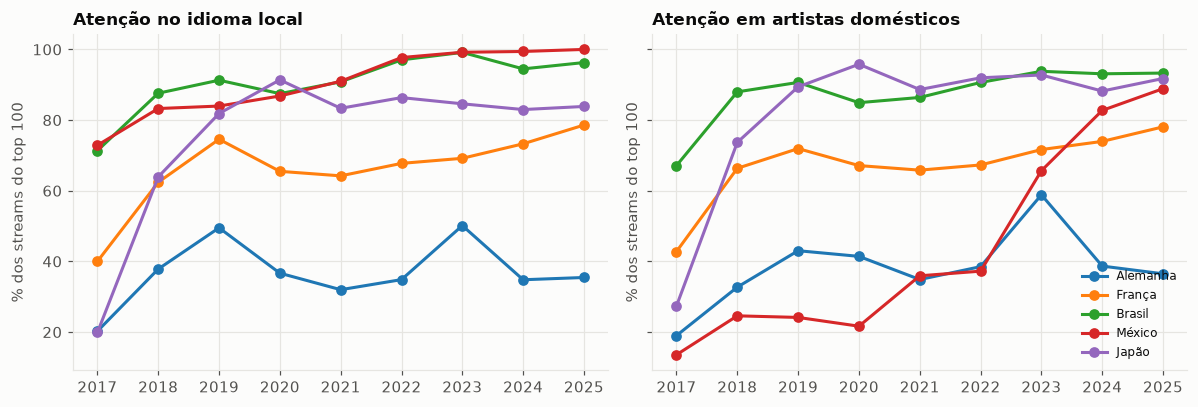

In [4]:
NAO_ANGLO = ["de", "fr", "br", "mx", "jp"]
forma = (d.assign(w_ling=d["peso_atencao"] * d["lingua_local"], w_dom=d["peso_atencao"] * d["domestico"].fillna(0))
           .groupby(["cc", "year"])[["w_ling", "w_dom"]].sum().rename(columns={"w_ling": "lingua_local", "w_dom": "domestico"})
           .reset_index())
linhas = []
for cc, g in forma.groupby("cc"):
    for col in ["lingua_local", "domestico"]:
        t = tendencia(g["year"], g[col])
        linhas.append({"cc": cc, "medida": col, "media": g[col].mean(), **t})
tend_forma = pd.DataFrame(linhas)
tend_forma["leitura"] = np.where(tend_forma["p"] < 0.05, np.where(tend_forma["inclinacao"] > 0, "sobe", "cai"), "estável")
display(tend_forma[tend_forma["cc"].isin(NAO_ANGLO)].round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, col, tit in zip(axes, ["lingua_local", "domestico"], ["Atenção no idioma local", "Atenção em artistas domésticos"]):
    for i, cc in enumerate(NAO_ANGLO):
        g = forma[forma["cc"] == cc]
        ax.plot(g["year"], g[col] * 100, marker="o", label=NOMES[cc])
    ax.set_title(tit, loc="left"); ax.set_ylabel("% dos streams do top 100")
axes[1].legend(loc="lower right", fontsize=8)
fig.tight_layout(); fig.savefig(PASTA_RES / "h1_forma_local.png"); plt.show()
forma.to_csv(PASTA_RES / "h1_forma_local.csv", index=False)
tend_forma.to_csv(PASTA_RES / "h1_forma_local_tendencias.csv", index=False)

## 4. Motor de similaridade: Wasserstein, bootstrap e nulo

Para cada par de países (a, b) e ano t: sim = 1 − W(nuvem_a, nuvem_b), com custo = 1 − cosseno. Pesos: cada música
vale 1/n (**repertório**) ou a sua fatia dos streams (**atenção**).

- **Bootstrap de Poisson pareado:** em cada réplica, cada música recebe um peso aleatório Poisson(1), e uma música que
  está em vários países no mesmo ano recebe **o mesmo peso em todos eles** (as matrizes de custo são calculadas uma vez;
  só os pesos mudam). Reamostrar cada país separadamente quebraria os pares de músicas idênticas (distância zero) e
  criaria um viés que muda com a fração de hits compartilhados em cada ano. A inclinação da série de cada grupo de
  pares dá o IC95% (percentil).
- **Nulo:** os rótulos de país são embaralhados entre as músicas do par no mesmo ano. É a similaridade esperada
  se o país não importasse; serve de régua para o valor observado.
- Uma série de grupo só usa pares presentes **em todos os anos** da variante (se o conjunto de pares mudasse entre
  anos, a tendência ficaria contaminada).

Outras métricas (robustez) usam o mesmo motor: MMD com kernel RBF, cosseno entre centroides e 1 − JS sobre tópicos.

In [5]:
GRUPOS = {
    "global": PARES,
    "mesmo idioma": [p for p in PARES if dist_ling(*p) == 0],
    "mesma família": [p for p in PARES if dist_ling(*p) == 1],
    "famílias diferentes": [p for p in PARES if dist_ling(*p) == 2],
    "H1b: ocidentais, idiomas diferentes": [p for p in PARES if "jp" not in p and dist_ling(*p) > 0],
    "Japão × outros": [p for p in PARES if "jp" in p],
}
print({g: len(v) for g, v in GRUPOS.items()})

def celulas(dsub, peso="repertorio", anos=None):
    cel = {}
    for (cc, y), g in dsub.groupby(["cc", "year"]):
        if anos is not None and y not in anos:
            continue
        if len(g) < MIN_CEL:
            continue
        w = np.ones(len(g)) if peso == "repertorio" else g["peso_atencao"].values.astype(float)
        cel[(cc, y)] = (g["ix"].values, w / w.sum(), g["chave"].values)
    return cel

# ---------- métricas: prepara(Xa, Xb) -> estado ; avalia(estado, wa, wb) -> similaridade
def _w_prep(Xa, Xb):
    return np.clip(1.0 - Xa @ Xb.T, 0, None).astype(np.float64)
def _w_eval(C, wa, wb):
    return 1.0 - ot.emd2(wa, wb, C)

SIGMA = {}
def _mmd_prep(Xa, Xb, s):
    k = lambda A, B: np.exp(-np.clip(1.0 - A @ B.T, 0, None) / s)
    return (k(Xa, Xa), k(Xb, Xb), k(Xa, Xb))
def _mmd_eval(K, wa, wb):
    v = wa @ K[0] @ wa + wb @ K[1] @ wb - 2 * wa @ K[2] @ wb
    return 1.0 - np.sqrt(max(v, 0.0))

def _cos_prep(Xa, Xb):
    return (Xa, Xb)
def _cos_eval(S, wa, wb):
    a, b = wa @ S[0], wb @ S[1]
    return float(a @ b / np.linalg.norm(a) / np.linalg.norm(b))

def _js_prep(Ta, Tb):
    return (Ta, Tb)
def _js_eval(S, wa, wb):
    return 1.0 - jensenshannon(wa @ S[0], wb @ S[1], base=2) ** 2

def metrica(nome, X):
    # X: matriz de representação das faixas (embeddings ou one-hot de tópicos)
    if nome == "wasserstein":
        return lambda ia, ib: _w_prep(X[ia], X[ib]), _w_eval
    if nome == "mmd":
        if "mmd" not in SIGMA:
            amostra = X[rng.choice(len(X), 1500, replace=False)]
            SIGMA["mmd"] = float(np.median(np.clip(1 - amostra @ amostra.T, 0, None)))
        return lambda ia, ib: _mmd_prep(X[ia], X[ib], SIGMA["mmd"]), _mmd_eval
    if nome == "cosseno":
        return lambda ia, ib: _cos_prep(X[ia], X[ib]), _cos_eval
    if nome == "js_topicos":
        return lambda ia, ib: _js_prep(X[ia], X[ib]), _js_eval
    raise ValueError(nome)

def _replicas(estados, cel, avalia, chaves_pp, n, semente):
    r = np.random.default_rng(semente)
    out = np.empty((n, len(chaves_pp)))
    anos = sorted({k[1] for k in cel})
    chaves_ano = {y: np.unique(np.concatenate([c[2] for k, c in cel.items() if k[1] == y])) for y in anos}
    pos_ano = {k: np.searchsorted(chaves_ano[k[1]], c[2]) for k, c in cel.items()}
    for b in range(n):
        peso = {y: r.poisson(1.0, len(chaves_ano[y])).astype(float) for y in anos}
        wb = {}
        for k, (ix, w, _) in cel.items():
            ww = w * peso[k[1]][pos_ano[k]]
            if ww.sum() == 0:
                ww = w.copy()
            wb[k] = ww / ww.sum()
        for j, (a, bb, y) in enumerate(chaves_pp):
            out[b, j] = avalia(estados[(a, bb, y)], wb[(a, y)], wb[(bb, y)])
    return out

def similaridades(dsub, X, nome_metrica="wasserstein", peso="repertorio", n_boot=N_BOOT, anos=None):
    # Retorna (tabela par-ano com a similaridade observada, matriz de réplicas bootstrap [n_boot x par-ano])
    cel = celulas(dsub, peso, anos)
    prep, avalia = metrica(nome_metrica, X)
    chaves_pp = [(a, b, y) for y in sorted({k[1] for k in cel}) for a, b in PARES if (a, y) in cel and (b, y) in cel]
    estados = {(a, b, y): prep(cel[(a, y)][0], cel[(b, y)][0]) for a, b, y in chaves_pp}
    obs = [avalia(estados[k], cel[(k[0], k[2])][1], cel[(k[1], k[2])][1]) for k in chaves_pp]
    tab = pd.DataFrame(chaves_pp, columns=["a", "b", "year"]).assign(sim=obs)
    tab["na"] = [len(cel[(a, y)][0]) for a, _, y in chaves_pp]
    tab["nb"] = [len(cel[(b, y)][0]) for _, b, y in chaves_pp]
    boot = np.empty((0, len(chaves_pp)))
    if n_boot:
        nj = max(1, min(os.cpu_count() or 1, 8) if N_JOBS == -1 else N_JOBS)
        partes = np.array_split(np.arange(n_boot), nj)
        res = Parallel(n_jobs=nj)(delayed(_replicas)(estados, cel, avalia, chaves_pp, len(p), SEED + i)
                                  for i, p in enumerate(partes) if len(p))
        boot = np.vstack(res)
    return tab, boot

def leitura(t):
    exclui = (t["ic95_lo"] > 0) or (t["ic95_hi"] < 0)
    if exclui and t["p"] < 0.05:
        return "convergência" if t["inclinacao"] > 0 else "divergência"
    if exclui:
        return "convergência fraca" if t["inclinacao"] > 0 else "divergência fraca"
    return "sem tendência"

def series_grupos(tab, boot, grupos=GRUPOS, anos_fora=()):
    # Série média de cada grupo, IC por ano e tendência com IC bootstrap da inclinação
    anos = sorted(set(tab["year"]) - set(anos_fora))
    tab = tab.reset_index(drop=True)
    pares_ano = tab.groupby(["a", "b"])["year"].apply(set)
    completos = {p for p, s in pares_ano.items() if set(anos) <= s}
    series, tends = [], []
    for g, pares in grupos.items():
        ps = [p for p in pares if p in completos]
        if not ps:
            continue
        cols = [[i for i in tab.index[(tab["year"] == y) & tab.set_index(["a", "b"]).index.isin(ps)]] for y in anos]
        y_obs = np.array([tab.loc[c, "sim"].mean() for c in cols])
        t = tendencia(anos, y_obs)
        if boot.shape[0]:
            yb = np.stack([boot[:, c].mean(axis=1) for c in cols], axis=1)            # n_boot x anos
            x = np.array(anos, float) - np.mean(anos)
            slopes = (yb - yb.mean(axis=1, keepdims=True)) @ x / (x @ x)
            t["ic95_lo"], t["ic95_hi"] = np.percentile(slopes, [2.5, 97.5])
            lo, hi = np.percentile(yb, [2.5, 97.5], axis=0)
        else:
            lo = hi = np.full(len(anos), np.nan)
        for y, v, l, h in zip(anos, y_obs, lo, hi):
            series.append({"grupo": g, "year": y, "sim": v, "lo": l, "hi": h, "n_pares": len(ps)})
        tends.append({"grupo": g, "n_pares": len(ps), "inclinacao": t["inclinacao"], "ic95_lo": t["ic95_lo"],
                      "ic95_hi": t["ic95_hi"], "p": t["p"], "leitura": leitura(t)})
    return pd.DataFrame(series), pd.DataFrame(tends)

def nulo_permutacao(dsub, X, n_perm=N_PERM, anos=None):
    # Similaridade (1 - W) esperada se o país não importasse: rótulos embaralhados dentro do par-ano
    cel = celulas(dsub, "repertorio", anos)
    linhas = []
    for y in sorted({k[1] for k in cel}):
        for a, b in PARES:
            if (a, y) not in cel or (b, y) not in cel:
                continue
            ia, ib = cel[(a, y)][0], cel[(b, y)][0]
            todos = np.concatenate([ia, ib]); C = np.clip(1 - X[todos] @ X[todos].T, 0, None).astype(np.float64)
            na, nb = len(ia), len(ib); v = []
            for _ in range(n_perm):
                p = rng.permutation(len(todos))
                v.append(1 - ot.emd2(np.full(na, 1 / na), np.full(nb, 1 / nb), C[np.ix_(p[:na], p[na:])]))
            linhas.append({"a": a, "b": b, "year": y, "sim_nulo": np.mean(v)})
    return pd.DataFrame(linhas)

def plota_series(series, grupos, titulo, arq, nulo=None):
    fig, ax = plt.subplots(figsize=(8.5, 4.2))
    cores = [COR["s1"], COR["s2"], COR["s3"], COR["s4"], "#e3a21a", "#555555"]
    for cor, g in zip(cores, grupos):
        s = series[series["grupo"] == g]
        if s.empty:
            continue
        ax.plot(s["year"], s["sim"], marker="o", color=cor, label=f"{g} ({s['n_pares'].iloc[0]} pares)")
        ax.fill_between(s["year"], s["lo"], s["hi"], color=cor, alpha=0.15, lw=0)
    if nulo is not None:
        ax.plot(nulo["year"], nulo["sim_nulo"], ls="--", color=COR["neutro"], label="nulo (país não importa), global")
    ax.set_title(titulo, loc="left"); ax.set_ylabel("similaridade (1 − Wasserstein)")
    ax.legend(fontsize=8, loc="best"); fig.tight_layout(); fig.savefig(PASTA_RES / arq); plt.show()

{'global': 36, 'mesmo idioma': 6, 'mesma família': 7, 'famílias diferentes': 23, 'H1b: ocidentais, idiomas diferentes': 22, 'Japão × outros': 8}


## 5. H1 — conteúdo: os países se aproximam?

Amostra principal: **estreias domésticas** (músicas de artistas do próprio país no primeiro ano em que entram no top
100), na letra traduzida. É o conteúdo novo produzido em cada país, sem hits importados nem permanências. Como
`estreia` não existe em 2017, a série vai de 2018 a 2025. A mesma análise com **todas as músicas** fica ao lado.

músicas por célula nas estreias domésticas (células com menos de 10 ficam de fora):


year,2018,2019,2020,2021,2022,2023,2024,2025
cc,,,,,,,,
us,37,29,33,24,17,20,18,19
gb,22,18,14,17,25,6,9,13
ca,17,10,8,10,7,8,7,6
au,15,14,11,13,8,10,9,14
de,32,35,37,28,29,41,25,23
fr,64,59,52,52,49,50,55,58
br,81,74,72,76,80,87,74,77
mx,24,12,18,22,28,50,60,63
jp,49,44,47,53,48,37,30,25



=== estreias domésticas (letra traduzida, repertório)


,grupo,n_pares,inclinacao,ic95_lo,ic95_hi,p,leitura
0,global,15,-0.0008,-0.0019,0.0003,0.1627,sem tendência
1,mesma família,4,-0.0000,-0.0011,0.0014,0.9617,sem tendência
2,famílias diferentes,11,-0.0011,-0.0023,0.0000,0.0796,sem tendência
3,"H1b: ocidentais, idiomas diferentes",10,-0.0006,-0.0016,0.0007,0.3986,sem tendência
4,Japão × outros,5,-0.0014,-0.0030,0.0000,0.0606,sem tendência



=== todas (letra traduzida, repertório)


,grupo,n_pares,inclinacao,ic95_lo,ic95_hi,p,leitura
0,global,36,-0.0075,-0.0093,-0.0054,0.0104,divergência
1,mesmo idioma,6,0.0010,-0.0016,0.0036,0.4594,sem tendência
2,mesma família,7,-0.0060,-0.0084,-0.0035,0.0327,divergência
3,famílias diferentes,23,-0.0102,-0.0120,-0.0079,0.0059,divergência
4,"H1b: ocidentais, idiomas diferentes",22,-0.0080,-0.0099,-0.0057,0.0037,divergência
5,Japão × outros,8,-0.0126,-0.0146,-0.0105,0.0308,divergência


global observado × nulo:


year,2017,2018,2019,2020,2021,2022,2023,2024,2025
observado,0.781,0.734,0.716,0.720,0.716,0.705,0.694,0.704,0.706
nulo,0.731,0.710,0.702,0.704,0.699,0.693,0.686,0.689,0.692


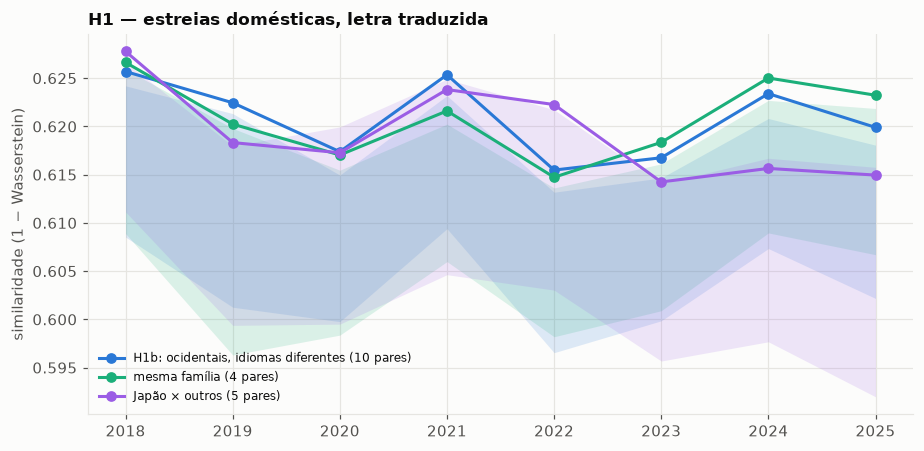

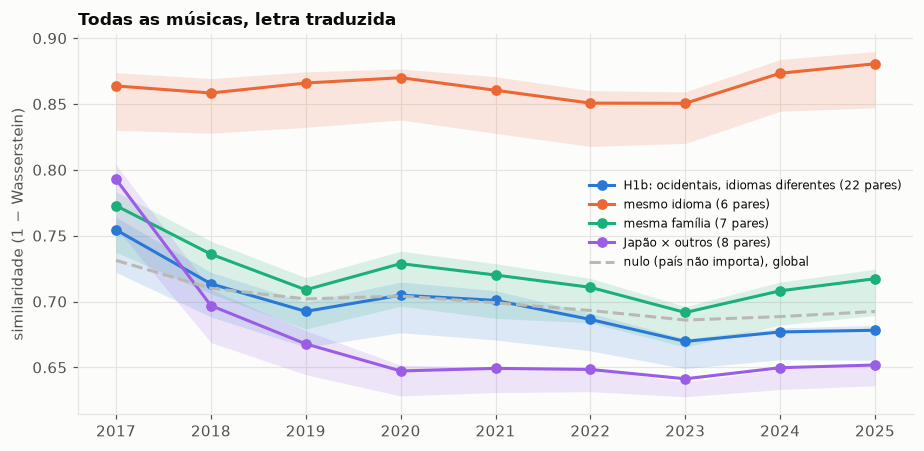

In [6]:
AMOSTRAS = {
    "todas": d,
    "estreias domésticas": d[(d["estreia"] == 1) & (d["domestico"] == 1)],
    "só estreias": d[d["estreia"] == 1],
    "só domésticas": d[d["domestico"] == 1],
    "sem catálogo": d[d["catalogo"] == 0],
    "só exclusivas": d[~d["compartilhada"]],
}
n_cel = AMOSTRAS["estreias domésticas"].groupby(["cc", "year"]).size().unstack()
print("músicas por célula nas estreias domésticas (células com menos de", MIN_CEL, "ficam de fora):")
display(n_cel.reindex(PAISES))

resultados_h1 = {}
for amostra in ["estreias domésticas", "todas"]:
    tab, boot = similaridades(AMOSTRAS[amostra], E["traduzida"])
    ser, tend = series_grupos(tab, boot)
    resultados_h1[amostra] = (tab, boot, ser, tend)
    print(f"\n=== {amostra} (letra traduzida, repertório)")
    display(tend.round(4))

nulo = nulo_permutacao(d, E["traduzida"])
nulo_glob = nulo.groupby("year")["sim_nulo"].mean().reset_index()
tab_t, _, ser_t, _ = resultados_h1["todas"]
obs_glob = tab_t.groupby("year")["sim"].mean()
print("global observado × nulo:")
display(pd.DataFrame({"observado": obs_glob, "nulo": nulo_glob.set_index("year")["sim_nulo"]}).round(3).T)

G_PLOT = ["H1b: ocidentais, idiomas diferentes", "mesmo idioma", "mesma família", "Japão × outros"]
plota_series(resultados_h1["estreias domésticas"][2], G_PLOT, "H1 — estreias domésticas, letra traduzida", "h1_series_estreias_domesticas.png")
plota_series(ser_t, G_PLOT, "Todas as músicas, letra traduzida", "h1_series_todas.png", nulo=nulo_glob)
for amostra, (tab, boot, ser, tend) in resultados_h1.items():
    slug = amostra.replace(" ", "_").replace("é", "e")
    tab.to_csv(PASTA_RES / f"h1_pares_{slug}.csv", index=False)
    ser.to_csv(PASTA_RES / f"h1_series_{slug}.csv", index=False)
    tend.to_csv(PASTA_RES / f"h1_tendencias_{slug}.csv", index=False)
nulo.to_csv(PASTA_RES / "h1_nulo_permutacao.csv", index=False)

### Tendência por par (FDR)

Inclinação da similaridade de cada par ao longo dos anos (todas as músicas, letra traduzida), com IC bootstrap e
p da regressão corrigido por Benjamini–Hochberg nos 36 pares.

,par,dist_ling,media,inclinacao,ic95_lo,ic95_hi,p,p_fdr,leitura
7,Canadá–Austrália,0,0.8979,0.0055,0.0019,0.0091,0.0025,0.0113,convergência
28,EUA–Austrália,0,0.8449,0.0020,-0.0026,0.0053,0.3435,0.3748,sem tendência
20,Reino Unido–Austrália,0,0.8768,0.0009,-0.0023,0.0042,0.5430,0.5750,sem tendência
22,Reino Unido–Canadá,0,0.8518,0.0006,-0.0027,0.0046,0.6895,0.7092,sem tendência
33,EUA–Reino Unido,0,0.8122,-0.0001,-0.0038,0.0034,0.9646,0.9646,sem tendência
30,EUA–Canadá,0,0.8989,-0.0026,-0.0065,0.0007,0.2343,0.2636,sem tendência
31,EUA–Alemanha,1,0.7419,-0.0041,-0.0078,-0.0004,0.1525,0.1894,divergência fraca
23,Reino Unido–Alemanha,1,0.7761,-0.0041,-0.0084,-0.0003,0.1903,0.2210,divergência fraca
1,Austrália–Alemanha,1,0.7770,-0.0042,-0.0084,-0.0005,0.1778,0.2134,divergência fraca
9,Canadá–Alemanha,1,0.7737,-0.0046,-0.0088,-0.0008,0.1188,0.1527,divergência fraca


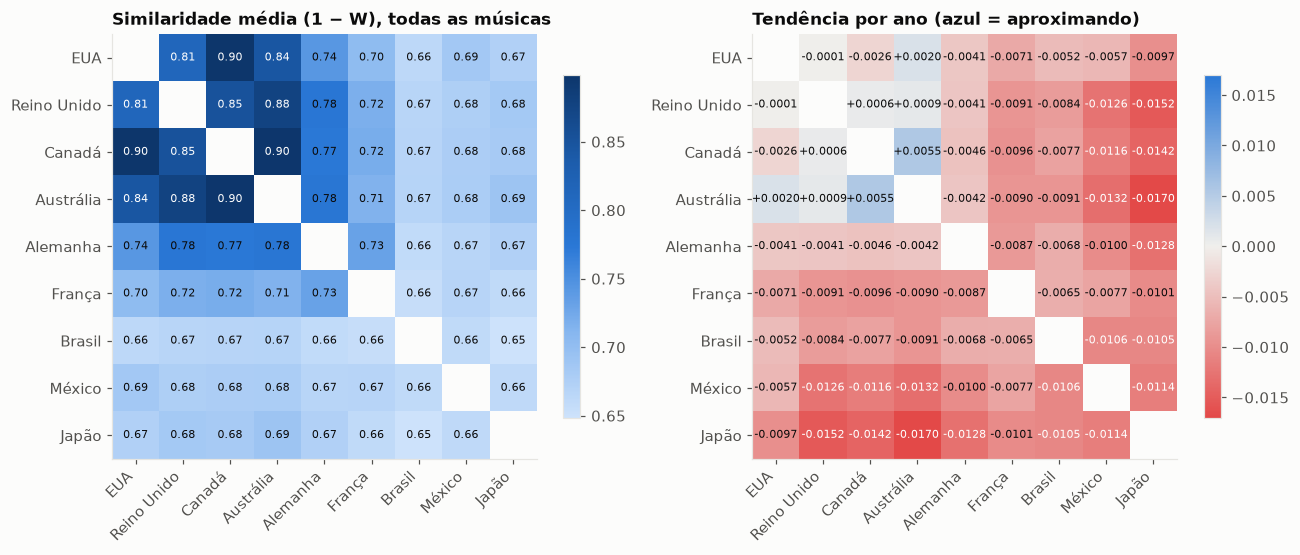

In [7]:
tab, boot, _, _ = resultados_h1["todas"]
x_anos = np.array(ANOS, float)
linhas = []
for (a, b), g in tab.groupby(["a", "b"]):
    g = g.sort_values("year")
    t = tendencia(g["year"], g["sim"])
    xb = g["year"].values - g["year"].mean()
    sl = (boot[:, g.index] - boot[:, g.index].mean(axis=1, keepdims=True)) @ xb / (xb @ xb)
    t["ic95_lo"], t["ic95_hi"] = np.percentile(sl, [2.5, 97.5])
    linhas.append({"a": a, "b": b, "par": f"{NOMES[a]}–{NOMES[b]}", "dist_ling": dist_ling(a, b),
                   "media": g["sim"].mean(), **t})
tend_pares = pd.DataFrame(linhas)
tend_pares["p_fdr"] = multipletests(tend_pares["p"], method="fdr_bh")[1]
tend_pares["leitura"] = [leitura({**r, "p": r["p_fdr"]}) for r in tend_pares.to_dict("records")]
display(tend_pares.sort_values("inclinacao", ascending=False).drop(columns=["a", "b"]).round(4))
tend_pares.to_csv(PASTA_RES / "h1_tendencia_pares.csv", index=False)

def matriz(col):
    M = pd.DataFrame(np.nan, index=PAISES, columns=PAISES)
    for r in tend_pares.itertuples():
        M.loc[r.a, r.b] = M.loc[r.b, r.a] = getattr(r, col)
    return M
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
im0 = plota_matriz(matriz("media"), "Similaridade média (1 − W), todas as músicas", axes[0], SEQ, fonte=7.5)
fig.colorbar(im0, ax=axes[0], shrink=0.75)
Mi = matriz("inclinacao"); lim = np.nanmax(np.abs(Mi.values))
im1 = plota_matriz(Mi, "Tendência por ano (azul = aproximando)", axes[1], DIV, vmin=-lim, vmax=lim, fmt="{:+.4f}", fonte=7)
fig.colorbar(im1, ax=axes[1], shrink=0.75)
fig.tight_layout(); fig.savefig(PASTA_RES / "h1_pares_matriz.png"); plt.show()

### Trajetórias: americanização ou convergência mútua?

Para cada país, o centroide das suas **músicas domésticas** em cada ano (letra traduzida). Comparamos esse
centroide com (a) o centroide de **tudo o que se ouve nos EUA** naquele ano e (b) a média dos centroides domésticos
dos **outros** países (sem EUA). Se (a) sobe mais que (b), a produção local está indo na direção do que os EUA ouvem.

,pais,→ EUA: inclinação,→ EUA: p,→ outros: inclinação,→ outros: p
0,Austrália,0.00233,0.00017,0.00049,0.16389
1,Brasil,0.00122,0.00080,0.00101,0.01803
2,Canadá,-0.00251,0.02226,0.00044,0.79339
3,Alemanha,0.00211,0.02702,0.00393,0.00187
4,França,-0.00082,0.23044,0.00223,0.02508
5,Reino Unido,0.00182,0.01669,0.00145,0.09793
6,Japão,0.00357,0.00321,0.00125,0.06860
7,México,0.00498,0.00036,0.00360,0.00012


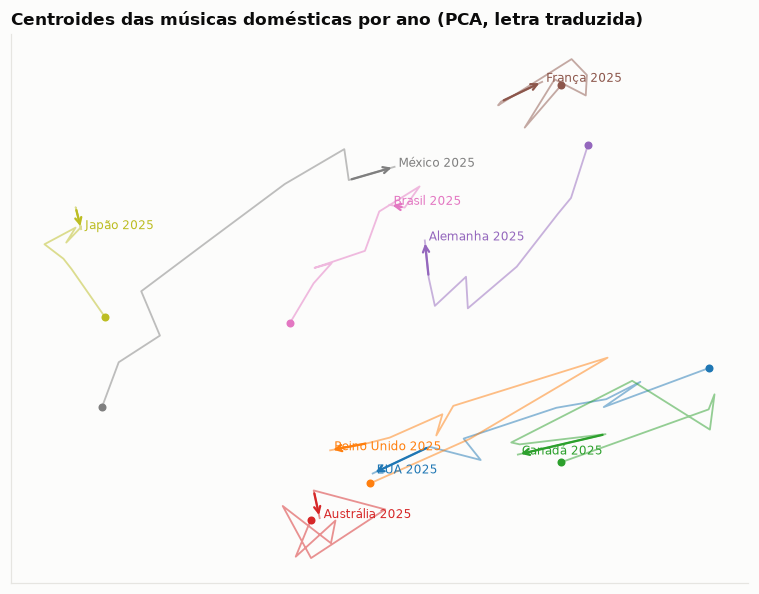

In [8]:
Xt = E["traduzida"]
def centroide(g):
    v = Xt[g["ix"].values].mean(axis=0); return v / np.linalg.norm(v)
dom = d[d["domestico"] == 1]
cent_dom = {(cc, y): centroide(g) for (cc, y), g in dom.groupby(["cc", "year"]) if len(g) >= MIN_CEL}
cent_us = {y: centroide(g) for y, g in d[d["cc"] == "us"].groupby("year")}
linhas = []
for (cc, y), v in cent_dom.items():
    if cc == "us":
        continue
    outros = [cent_dom[(o, y)] for o in PAISES if o not in (cc, "us") and (o, y) in cent_dom]
    linhas.append({"cc": cc, "year": y, "sim_eua": float(v @ cent_us[y]),
                   "sim_outros": float(np.mean([v @ o for o in outros]))})
traj = pd.DataFrame(linhas)
linhas = []
for cc, g in traj.groupby("cc"):
    a, b = tendencia(g["year"], g["sim_eua"]), tendencia(g["year"], g["sim_outros"])
    linhas.append({"pais": NOMES[cc], "→ EUA: inclinação": a["inclinacao"], "→ EUA: p": a["p"],
                   "→ outros: inclinação": b["inclinacao"], "→ outros: p": b["p"]})
tend_traj = pd.DataFrame(linhas)
display(tend_traj.round(5))

from sklearn.decomposition import PCA
ks = sorted(cent_dom); M = np.stack([cent_dom[k] for k in ks]); Z = PCA(2, random_state=SEED).fit_transform(M)
fig, ax = plt.subplots(figsize=(7, 5.5))
cores = dict(zip(PAISES, plt.cm.tab10.colors))
for cc in PAISES:
    pts = [(k[1], z) for k, z in zip(ks, Z) if k[0] == cc]
    if len(pts) < 2:
        continue
    pts.sort(key=lambda p: p[0]); P = np.array([p[1] for p in pts])
    ax.plot(P[:, 0], P[:, 1], color=cores[cc], alpha=0.5, lw=1.2)
    ax.annotate("", xy=P[-1], xytext=P[-2], arrowprops=dict(arrowstyle="->", color=cores[cc], lw=1.5))
    ax.text(*P[-1], f" {NOMES[cc]} {pts[-1][0]}", fontsize=8, color=cores[cc])
    ax.scatter(*P[0], color=cores[cc], s=18)
ax.set_title("Centroides das músicas domésticas por ano (PCA, letra traduzida)", loc="left")
ax.set_xticks([]); ax.set_yticks([])
fig.tight_layout(); fig.savefig(PASTA_RES / "h1_trajetorias.png"); plt.show()
traj.to_csv(PASTA_RES / "h1_trajetorias.csv", index=False)

## 6. Tópicos (BERTopic) — em quê os países se aproximam?

BERTopic sobre os embeddings da letra traduzida: UMAP → HDBSCAN → c-TF-IDF (palavras típicas de cada grupo). Ajuste
único com todas as músicas de todos os anos, para que os tópicos sejam os mesmos no período inteiro. As músicas que o
HDBSCAN deixa como ruído são realocadas ao tópico mais próximo (`reduce_outliers`).

Dois níveis: **finos** (o que o HDBSCAN encontra) e **grossos** (os finos fundidos em 8). A estabilidade é medida
pelo ARI entre 5 sementes do UMAP.

In [9]:
from bertopic import BERTopic
from umap import UMAP
from hdbscan import HDBSCAN
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS

MIN_TOPICO = 25
PALAVRAS_VAZIAS = list(ENGLISH_STOP_WORDS | {"oh", "ooh", "yeah", "ya", "yo", "la", "na", "da", "eh", "ah", "uh", "hey",
    "woah", "whoa", "mm", "hmm", "ay", "ey", "gonna", "wanna", "gotta", "got", "just", "like", "know", "don", "ll",
    "ve", "re", "let", "come", "say", "said", "make", "cause", "baby", "want", "get", "go", "im", "dont", "aint"})
docs = faixas["letra_en_limpa"].tolist()

def ajusta_bertopic(semente):
    m = BERTopic(umap_model=UMAP(n_neighbors=15, n_components=5, min_dist=0.0, metric="cosine", random_state=semente),
                 hdbscan_model=HDBSCAN(min_cluster_size=MIN_TOPICO, metric="euclidean", cluster_selection_method="eom",
                                       prediction_data=True),
                 vectorizer_model=CountVectorizer(stop_words=PALAVRAS_VAZIAS, min_df=1, token_pattern=r"(?u)\b[a-z]{3,}\b"),
                 calculate_probabilities=False, verbose=False)
    top, _ = m.fit_transform(docs, Xt)
    top = m.reduce_outliers(docs, top, strategy="embeddings", embeddings=Xt)
    m.update_topics(docs, topics=top, vectorizer_model=m.vectorizer_model)
    return m, np.array(top)

tm, top_fino = ajusta_bertopic(SEED)
tm_grosso = copy.deepcopy(tm)
tm_grosso.reduce_topics(docs, nr_topics=8)
top_grosso = np.array(tm_grosso.topics_)
print(f"tópicos finos: {len(set(top_fino))} | grossos: {len(set(top_grosso))}")

ari = [adjusted_rand_score(top_fino, ajusta_bertopic(s)[1]) for s in [7, 123, 2024, 99]]
print(f"estabilidade (ARI dos tópicos finos entre sementes): {np.mean(ari):.2f} (min {np.min(ari):.2f})")

def resumo_topicos(modelo, rot):
    linhas = []
    for t in sorted(set(rot)):
        palavras = ", ".join(w for w, _ in modelo.get_topic(t)[:8])
        tr = faixas.index[rot == t]
        comp = d[d["track_id"].isin(tr)]["cc"].value_counts(normalize=True).head(3)
        idi = faixas.loc[tr, "idioma"].value_counts(normalize=True).head(2)
        linhas.append({"topico": t, "faixas": len(tr), "palavras": palavras,
                       "paises": ", ".join(f"{NOMES[c]} {v:.0%}" for c, v in comp.items()),
                       "idiomas": ", ".join(f"{i} {v:.0%}" for i, v in idi.items())})
    return pd.DataFrame(linhas)

top_g = resumo_topicos(tm_grosso, top_grosso); top_f = resumo_topicos(tm, top_fino)
display(top_g)
top_g.to_csv(PASTA_RES / "topicos_grossos.csv", index=False); top_f.to_csv(PASTA_RES / "topicos_finos.csv", index=False)
d["topico"] = d["track_id"].map(dict(zip(faixas.index, top_grosso)))
d["topico_fino"] = d["track_id"].map(dict(zip(faixas.index, top_fino)))

/home/besome/Documentos/Coding/socialComp/SocialComp/.venv/lib64/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


2026-11-17 10:27:48,132 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.


tópicos finos: 4 | grossos: 4


2026-11-17 10:28:05,371 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.


2026-11-17 10:28:22,090 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.


2026-11-17 10:28:38,740 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.


2026-11-17 10:28:55,268 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.


estabilidade (ARI dos tópicos finos entre sementes): 0.72 (min 0.03)


,topico,faixas,palavras,paises,idiomas
0,0,1919,"going, youre, love, thats, fuck, ill, right, life","França 18%, Brasil 14%, México 13%","en 28%, fr 22%"
1,1,2089,"love, youre, going, time, ill, ive, night, feel","Japão 16%, Austrália 14%, Reino Unido 13%","en 46%, ja 16%"
2,2,33,"anddale, salam, european, shall, love, shes, y...","Brasil 43%, México 26%, Alemanha 20%","pt 45%, es 27%"
3,3,34,"feet, bum, pushing, ohoh, going, ohohohoh, lov...","Japão 29%, Brasil 17%, México 15%","pt 29%, es 24%"


### Prevalência dos tópicos e NMI tópico × país

Prevalência = fatia da atenção (streams) em cada tópico grosso, por país. O mapa mostra a **mudança** entre o início
(2017–2019) e o fim (2023–2025). NMI(tópico, país) ano a ano: se cai, os tópicos deixam de ser marcas de país
(homogeneização); NMI(tópico, idioma) mostra quanto os tópicos ainda seguem a língua mesmo com a tradução.

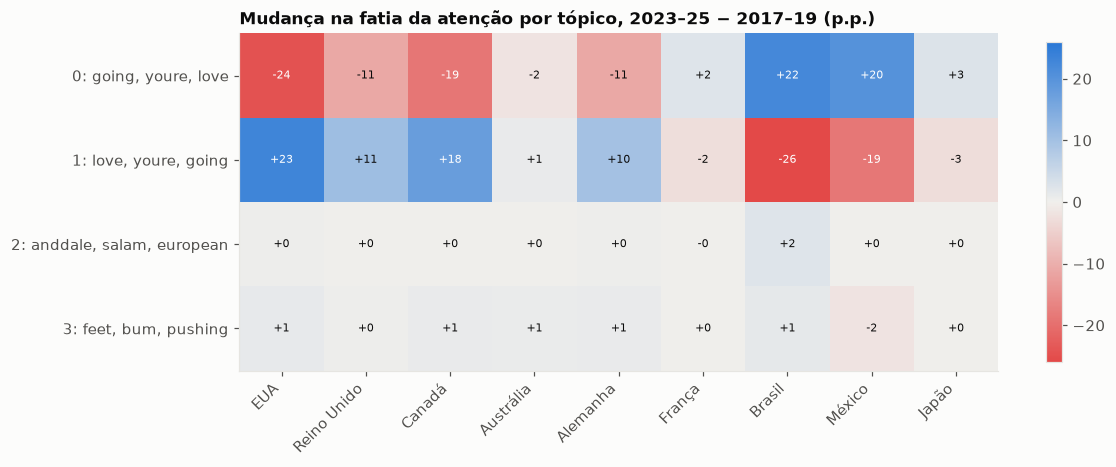

,0,1,2,3,4,5,6,7,8
year,2017.000,2018.000,2019.000,2020.000,2021.000,2022.000,2023.000,2024.000,2025.000
NMI tópico × país,0.030,0.044,0.054,0.056,0.045,0.045,0.055,0.043,0.064
NMI tópico × idioma,0.079,0.073,0.094,0.103,0.091,0.098,0.105,0.092,0.126


NMI tópico × país: +0.0021/ano, p = 0.114
NMI tópico × idioma: +0.0043/ano, p = 0.015


In [10]:
prev = d.groupby(["cc", "year", "topico"])["peso_atencao"].sum().unstack(fill_value=0)
ini = prev[prev.index.get_level_values("year") <= ANOS[0] + 2].groupby("cc").mean()
fim = prev[prev.index.get_level_values("year") >= ANOS[-1] - 2].groupby("cc").mean()
nomes_top = {r.topico: f"{r.topico}: " + ", ".join(r.palavras.split(", ")[:3]) for r in top_g.itertuples()}
delta = ((fim - ini) * 100).reindex(PAISES).rename(columns=nomes_top)
fig, ax = plt.subplots(figsize=(11, 4.5))
lim = np.nanmax(np.abs(delta.values))
im = plota_matriz(delta.T, "Mudança na fatia da atenção por tópico, 2023–25 − 2017–19 (p.p.)", ax, DIV, vmin=-lim, vmax=lim,
                  fmt="{:+.0f}", fonte=7.5)
ax.set_yticks(range(len(delta.columns)), delta.columns)
fig.colorbar(im, ax=ax, shrink=0.8); fig.tight_layout(); fig.savefig(PASTA_RES / "topicos_mudanca.png"); plt.show()

nmi = pd.DataFrame([{"year": y, "NMI tópico × país": normalized_mutual_info_score(g["cc"], g["topico_fino"]),
                     "NMI tópico × idioma": normalized_mutual_info_score(g["idioma"], g["topico_fino"])}
                    for y, g in d.groupby("year")])
display(nmi.round(3).T)
for col in ["NMI tópico × país", "NMI tópico × idioma"]:
    t = tendencia(nmi["year"], nmi[col]); print(f"{col}: {t['inclinacao']:+.4f}/ano, p = {t['p']:.3f}")
prev.to_csv(PASTA_RES / "topicos_prevalencia.csv"); nmi.to_csv(PASTA_RES / "topicos_nmi.csv", index=False)

### Temas fixos (classificação por similaridade) e amostra para anotação

Contraprova dos tópicos com uma taxonomia definida por nós: cada letra traduzida é comparada com a descrição de 10
temas (vetores gerados pelo `pipelineGPU`); a mistura de temas de cada música é um softmax das similaridades.
A validação humana usa 150 músicas sorteadas (estratificadas por país): a planilha vai para `dados/cache/` (fora do
git, porque tem letras). Quando ela voltar preenchida por duas pessoas (`dados/anotacao_temas_feita.csv`, colunas
`track_id`, `anotador`, `tema`), a célula seguinte calcula o kappa.

In [11]:
TAU = 0.02
arq_t = PASTA_EMB / f"temas__{EMB}.npz"
TEMAS = None
if arq_t.exists():
    z = np.load(arq_t); TEMAS = list(z["temas"]); T = z["emb"]
    S = Xt @ T.T
    P = np.exp((S - S.max(axis=1, keepdims=True)) / TAU); P /= P.sum(axis=1, keepdims=True)
    temas_df = pd.DataFrame(P, index=faixas.index, columns=TEMAS)
    temas_df["tema"] = temas_df[TEMAS].idxmax(axis=1)
    for t in TEMAS:
        d[f"tema_{t}"] = d["track_id"].map(temas_df[t])
    prev_t = (d.groupby(["cc"])[[f"tema_{t}" for t in TEMAS]].mean() * 100).reindex(PAISES)
    prev_t.index = prev_t.index.map(NOMES); prev_t.columns = TEMAS
    display(prev_t.round(0))
    print("concordância tema × tópico grosso (NMI):",
          round(normalized_mutual_info_score(temas_df["tema"], top_grosso), 3))
    amostra = (d.drop_duplicates("track_id").groupby("cc").sample(17, random_state=SEED)
                 .head(150)[["track_id", "cc", "title", "artists", "letra_en_limpa"]])
    amostra["tema_modelo"] = amostra["track_id"].map(temas_df["tema"])
    PASTA_CACHE.mkdir(parents=True, exist_ok=True)
    amostra.drop(columns=["tema_modelo"]).assign(anotador="", tema="").to_csv(PASTA_CACHE / "anotacao_temas.csv", index=False)
    print("planilha de anotação:", PASTA_CACHE / "anotacao_temas.csv", "| temas válidos:", TEMAS)
    arq_anot = PASTA_DADOS / "anotacao_temas_feita.csv"
    if arq_anot.exists():
        an = pd.read_csv(arq_anot).pivot_table(index="track_id", columns="anotador", values="tema", aggfunc="first").dropna()
        a1, a2 = an.columns[:2]
        print(f"kappa entre anotadores: {cohen_kappa_score(an[a1], an[a2]):.2f} ({len(an)} músicas)")
        acordo = an[an[a1] == an[a2]]
        print(f"acordo modelo × anotadores (onde eles concordam): {(acordo[a1] == temas_df.loc[acordo.index, 'tema']).mean():.0%}")
else:
    print(f"{arq_t} não encontrado: rode o pipelineGPU.ipynb")

,amor,termino,festa,dinheiro_status,sexo,violencia_rua,superacao,nostalgia,espiritualidade,critica_social
cc,,,,,,,,,,
EUA,28.0,18.0,24.0,5.0,1.0,3.0,2.0,19.0,0.0,0.0
Reino Unido,32.0,17.0,23.0,3.0,1.0,1.0,2.0,19.0,1.0,0.0
Canadá,30.0,17.0,24.0,4.0,1.0,2.0,2.0,19.0,0.0,0.0
Austrália,32.0,18.0,22.0,3.0,1.0,1.0,2.0,21.0,1.0,0.0
Alemanha,28.0,13.0,28.0,5.0,1.0,3.0,2.0,20.0,1.0,0.0
França,24.0,16.0,25.0,5.0,1.0,5.0,3.0,19.0,1.0,1.0
Brasil,31.0,20.0,26.0,2.0,2.0,1.0,2.0,15.0,1.0,0.0
México,29.0,21.0,24.0,4.0,1.0,2.0,2.0,17.0,0.0,0.0
Japão,26.0,21.0,10.0,2.0,0.0,0.0,3.0,36.0,0.0,0.0


concordância tema × tópico grosso (NMI): 0.087
planilha de anotação: /home/besome/Documentos/Coding/socialComp/SocialComp/dados/cache/anotacao_temas.csv | temas válidos: [np.str_('amor'), np.str_('termino'), np.str_('festa'), np.str_('dinheiro_status'), np.str_('sexo'), np.str_('violencia_rua'), np.str_('superacao'), np.str_('nostalgia'), np.str_('espiritualidade'), np.str_('critica_social')]


## 7. H2 — gradiente linguístico (regressão diádica com QAP)

Uma linha por par e ano. Variáveis:

- `sim`: 1 − Wasserstein, todas as músicas, repertório;
- `mesma_familia`, `familias_dif`: distância linguística (referência = mesmo idioma);
- `t`: ano centrado; interações com a distância (a barreira muda com o tempo?);
- `jaccard`: fração de músicas em comum entre os dois top 100 (hits compartilhados);
- `inercia`: média da fração do top 100 repetida do ano anterior nos dois países (só a partir de 2018);
- `japao`: o par envolve o Japão.

Os pares não são independentes (cada país aparece em 8 pares), então a inferência é por **QAP**: os rótulos dos 9
países são permutados na matriz de similaridade (a mesma permutação em todos os anos) e o modelo é reajustado.
p = fração das permutações com |β| ≥ |β observado|.

**H2 confirma se** os coeficientes da distância são negativos (mais distância, menos similaridade) e as interações
com o tempo ficam perto de zero. Comparar letra original × traduzida mostra quanto da barreira é língua.

beta              p_qap         
versao                               traduzida original traduzida original
modelo               coef                                                 
M1 distância × tempo const              0.8637   0.8630    0.0045   0.0025
                     mesma_familia     -0.1421  -0.1549    0.0170   0.0300
                     familias_dif      -0.1826  -0.2130    0.0005   0.0000
                     t                  0.0010   0.0009    0.9865   0.9970
                     mesma_familia:t   -0.0070  -0.0072    0.0490   0.0920
                     familias_dif:t    -0.0112  -0.0127    0.0000   0.0000
M2 + hits em comum   const              0.6410   0.6067    0.7245   0.7060
                     mesma_familia      0.0141   0.0248    0.8605   0.8035
                     familias_dif       0.0093   0.0077    0.9060   0.9250
                     t                 -0.0012  -0.0017    0.9900   0.9865
                     mesma_familia:t    0.0001   0.0009    0.9900   0.8675
                     familias_dif:t    -0.0013  -0.0013    0.7535   0.8130
                     jaccard            0.5098   0.5864    0.0175   0.0235
M3 + Japão           const              0.6393   0.6086    0.7195   0.6960
                     mesma_familia      0.0153   0.0235    0.8660   0.8140
                     familias_dif       0.0111   0.0105    0.8720   0.9035
                     t                 -0.0020  -0.0024    0.9815   0.9850
                     jaccard            0.5136   0.5821    0.0185   0.0150
                     japao             -0.0012  -0.0129    0.9875   0.9275
M4 + Japão + inércia const              0.6271   0.5971    0.7455   0.7440
                     mesma_familia      0.0159   0.0231    0.8640   0.8480
                     familias_dif       0.0096   0.0069    0.9285   0.9555
                     t                 -0.0033  -0.0039    0.5960   0.5900
                     jaccard            0.5036   0.5644    0.0275   0.0440
                     japao             -0.0092  -0.0238    0.9410   0.8455
                     inercia            0.0619   0.0720    0.7810   0.7905

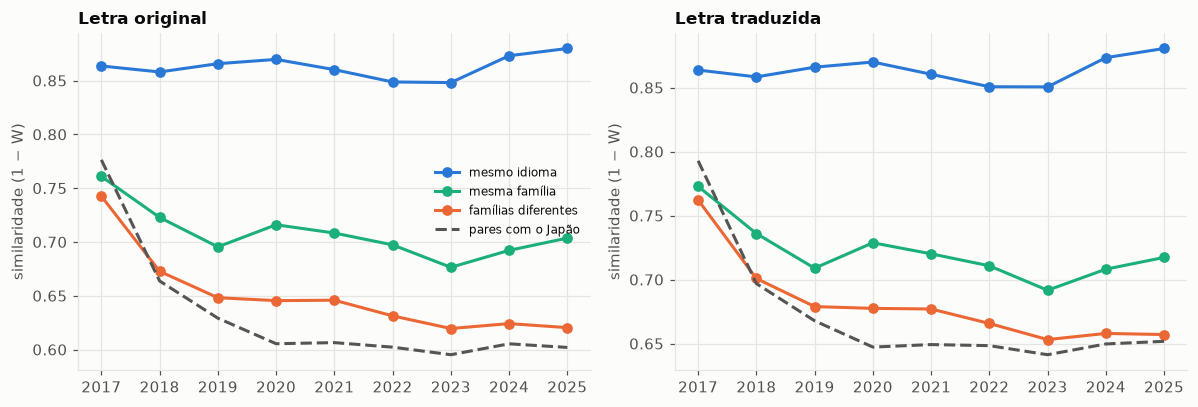

In [12]:
cel_ch = d.groupby(["cc", "year"])["chave"].apply(set)
rep = d.groupby(["cc", "year"])["repetida"].mean()
def tabela_diadica(versao):
    tab, _ = similaridades(d, E[versao], n_boot=0)
    tab["dist"] = [dist_ling(a, b) for a, b in zip(tab["a"], tab["b"])]
    tab["mesma_familia"] = (tab["dist"] == 1).astype(float); tab["familias_dif"] = (tab["dist"] == 2).astype(float)
    tab["t"] = tab["year"] - np.mean(ANOS)
    tab["mesma_familia:t"] = tab["mesma_familia"] * tab["t"]; tab["familias_dif:t"] = tab["familias_dif"] * tab["t"]
    tab["jaccard"] = [len(cel_ch[(a, y)] & cel_ch[(b, y)]) / len(cel_ch[(a, y)] | cel_ch[(b, y)]) for a, b, y in zip(tab["a"], tab["b"], tab["year"])]
    tab["inercia"] = [(rep.get((a, y), np.nan) + rep.get((b, y), np.nan)) / 2 for a, b, y in zip(tab["a"], tab["b"], tab["year"])]
    tab["japao"] = ((tab["a"] == "jp") | (tab["b"] == "jp")).astype(float)
    return tab

def ols(tab, X, y="sim"):
    A = np.column_stack([np.ones(len(tab))] + [tab[c].values for c in X])
    return np.linalg.lstsq(A, tab[y].values, rcond=None)[0]

def qap(tab, X, n=N_QAP):
    beta = ols(tab, X)
    idx = {p: i for i, p in enumerate(PAISES)}
    Y = {(a, b, y): s for a, b, y, s in zip(tab["a"], tab["b"], tab["year"], tab["sim"])}
    nulos = np.empty((n, len(beta)))
    for k in range(n):
        pi = dict(zip(PAISES, rng.permutation(PAISES)))
        ys = []
        for a, b, y in zip(tab["a"], tab["b"], tab["year"]):
            pa, pb = pi[a], pi[b]
            if idx[pa] > idx[pb]:
                pa, pb = pb, pa
            ys.append(Y[(pa, pb, y)])
        nulos[k] = ols(tab.assign(sim=ys), X)
    p = (np.abs(nulos) >= np.abs(beta)).mean(axis=0)
    return pd.DataFrame({"coef": ["const"] + X, "beta": beta, "p_qap": p})

MODELOS = {
    "M1 distância × tempo": ["mesma_familia", "familias_dif", "t", "mesma_familia:t", "familias_dif:t"],
    "M2 + hits em comum": ["mesma_familia", "familias_dif", "t", "mesma_familia:t", "familias_dif:t", "jaccard"],
    "M3 + Japão": ["mesma_familia", "familias_dif", "t", "jaccard", "japao"],
    "M4 + Japão + inércia": ["mesma_familia", "familias_dif", "t", "jaccard", "japao", "inercia"],
}
saida = []
diad = {}
for versao in ["traduzida", "original"]:
    tab = tabela_diadica(versao); diad[versao] = tab
    for nome, X in MODELOS.items():
        tb = tab.dropna(subset=X) if "inercia" in X else tab
        r = qap(tb, X).assign(versao=versao, modelo=nome, n=len(tb),
                              r2=1 - np.var(tb["sim"] - np.column_stack([np.ones(len(tb))] + [tb[c] for c in X]) @ ols(tb, X)) / np.var(tb["sim"]))
        saida.append(r)
h2 = pd.concat(saida, ignore_index=True)
display(h2.pivot_table(index=["modelo", "coef"], columns="versao", values=["beta", "p_qap"], sort=False).round(4))
h2.to_csv(PASTA_RES / "h2_qap.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=False)
rot = {0: "mesmo idioma", 1: "mesma família", 2: "famílias diferentes"}
for ax, versao in zip(axes, ["original", "traduzida"]):
    g = diad[versao].groupby(["year", "dist"])["sim"].mean().unstack()
    for cor, k in zip([COR["s1"], COR["s3"], COR["s2"]], [0, 1, 2]):
        ax.plot(g.index, g[k], marker="o", color=cor, label=rot[k])
    jp = diad[versao][diad[versao]["japao"] == 1].groupby("year")["sim"].mean()
    ax.plot(jp.index, jp.values, ls="--", color="#555555", label="pares com o Japão")
    ax.set_title(f"Letra {versao}", loc="left"); ax.set_ylabel("similaridade (1 − W)")
axes[0].legend(fontsize=8)
fig.tight_layout(); fig.savefig(PASTA_RES / "h2_niveis.png"); plt.show()

## 8. H3 — estilo × tema

**Medidas de estilo por música:**

- **code-switching**: % das linhas em inglês, só nas músicas cuja língua não é o inglês (cada linha com ≥ 3 palavras
  que não sejam vocalizações é classificada pelo `lingua` entre o inglês e a língua da música; linhas com kana/kanji
  contam como japonês);
- **repetição**: 1 − linhas distintas / linhas;
- **compressibilidade**: tamanho gzip / tamanho original (quanto menor, mais repetitiva/formulaica);
- **toxicidade** (Detoxify) e **sentimento** (XLM-T, letra original), do `pipelineGPU`.

**Medidas de tema:** a mistura dos 10 temas fixos e a fatia de cada tópico grosso.

**Teste:** para cada medida e ano, η² = fração da variância entre músicas explicada pelo país. Se os países
convergem numa medida, η² cai. H3 confirma se a inclinação média do η² das medidas de estilo é mais negativa que a
das medidas de tema (IC bootstrap da diferença exclui 0).

In [13]:
from lingua import Language, LanguageDetectorBuilder
LING = {"es": Language.SPANISH, "pt": Language.PORTUGUESE, "fr": Language.FRENCH, "de": Language.GERMAN, "ja": Language.JAPANESE}
VOCAL = {"oh", "ooh", "ah", "eh", "uh", "yeah", "yeh", "la", "na", "da", "hey", "ay", "ey", "woah", "whoa", "mm", "hmm",
         "ha", "yo", "ye", "ya", "uoh", "oh-oh", "na-na", "la-la"}
CJK = re.compile(r"[぀-ヿ一-鿿]")
arq_cs = PASTA_CACHE / "code_switching.csv"
if arq_cs.exists():
    cs = pd.read_csv(arq_cs, index_col=0)
else:
    dets = {k: LanguageDetectorBuilder.from_languages(Language.ENGLISH, v).build() for k, v in LING.items()}
    linhas = []
    for tid, r in faixas[faixas["idioma"].isin(LING)].iterrows():
        n_val = n_en = 0
        for l in r["letra_limpa"].split("\n"):
            pal = [w for w in re.findall(r"[^\W\d_]+", l.lower()) if w not in VOCAL]
            if r["idioma"] == "ja" and CJK.search(l):
                n_val += 1; continue
            if len(pal) < 3:
                continue
            n_val += 1
            n_en += dets[r["idioma"]].detect_language_of(l) == Language.ENGLISH
        linhas.append({"track_id": tid, "linhas_validas": n_val, "linhas_en": n_en})
    cs = pd.DataFrame(linhas).set_index("track_id")
    cs.to_csv(arq_cs)
cs["code_switching"] = cs["linhas_en"] / cs["linhas_validas"].replace(0, np.nan)

def repeticao(t):
    l = [x.strip().lower() for x in t.split("\n") if x.strip()]
    return 1 - len(set(l)) / len(l) if l else np.nan
def compressao(t):
    b = t.encode("utf-8"); return len(gzip.compress(b)) / len(b) if b else np.nan

estilo = pd.DataFrame(index=faixas.index)
estilo["code_switching"] = cs["code_switching"]
estilo["repeticao"] = faixas["letra_limpa"].map(repeticao)
estilo["compressao"] = faixas["letra_limpa"].map(compressao)
arq_tox, arq_sent = PASTA_DADOS / "toxicidade.csv", PASTA_DADOS / "sentimento.csv"
tox = pd.read_csv(arq_tox, index_col=0) if arq_tox.exists() else None
sent = pd.read_csv(arq_sent, index_col=0) if arq_sent.exists() else None
if tox is not None and tox.index.isin(faixas.index).mean() > 0.95 and faixas.index.isin(tox.index).mean() > 0.95:
    estilo["toxicidade"] = tox["tox"].reindex(estilo.index)
else:
    print("toxicidade.csv ausente ou incompleto para os 9 países: rode o pipelineGPU.ipynb"); tox = None
if sent is not None and faixas.index.isin(sent.index).mean() > 0.95:
    estilo["sentimento"] = sent["orig_sent"].reindex(estilo.index)
else:
    print("sentimento.csv ausente ou incompleto: rode o pipelineGPU.ipynb"); sent = None
for c in estilo.columns:
    d[c] = d["track_id"].map(estilo[c])

g = d.groupby("cc")[list(estilo.columns)].mean().reindex(PAISES); g.index = g.index.map(NOMES)
display(g.round(3))
print("code-switching (% de linhas em inglês) por país e ano, músicas não inglesas:")
display((d.groupby(["cc", "year"])["code_switching"].mean().unstack() * 100).round(0).reindex([c for c in PAISES if c in NAO_ANGLO]))

toxicidade.csv ausente ou incompleto para os 9 países: rode o pipelineGPU.ipynb


,code_switching,repeticao,compressao,sentimento
cc,,,,
EUA,0.042,0.309,0.359,-0.012
Reino Unido,0.055,0.375,0.328,0.006
Canadá,0.048,0.341,0.343,-0.005
Austrália,0.015,0.365,0.332,0.001
Alemanha,0.052,0.402,0.328,-0.009
França,0.043,0.350,0.344,0.014
Brasil,0.014,0.452,0.308,-0.043
México,0.025,0.295,0.391,0.020
Japão,0.027,0.247,0.414,0.032


code-switching (% de linhas em inglês) por país e ano, músicas não inglesas:


year,2017,2018,2019,2020,2021,2022,2023,2024,2025
cc,,,,,,,,,
de,5.0,5.0,7.0,3.0,5.0,6.0,4.0,8.0,4.0
fr,4.0,4.0,4.0,4.0,5.0,3.0,5.0,4.0,5.0
br,1.0,1.0,2.0,2.0,1.0,1.0,2.0,1.0,1.0
mx,3.0,3.0,2.0,3.0,3.0,3.0,2.0,3.0,2.0
jp,6.0,4.0,3.0,3.0,3.0,1.0,1.0,3.0,3.0


,medida,grupo,eta2_medio,inclinacao_eta2
0,code_switching,estilo,0.05145,0.00058
1,repeticao,estilo,0.14736,0.00165
2,compressao,estilo,0.17636,0.01105
3,sentimento,estilo,0.03401,0.00085
4,tema_amor,tema,0.01940,0.00097
5,tema_termino,tema,0.02123,-0.00107
6,tema_festa,tema,0.03753,0.00164
7,tema_dinheiro_status,tema,0.03087,-0.00010
8,tema_sexo,tema,0.01943,0.00033
9,tema_violencia_rua,tema,0.04004,-0.00463


H3: inclinação média do η² (estilo − tema) = +0.00271 | IC95% [-0.00147, +0.00545] -> sem diferença clara


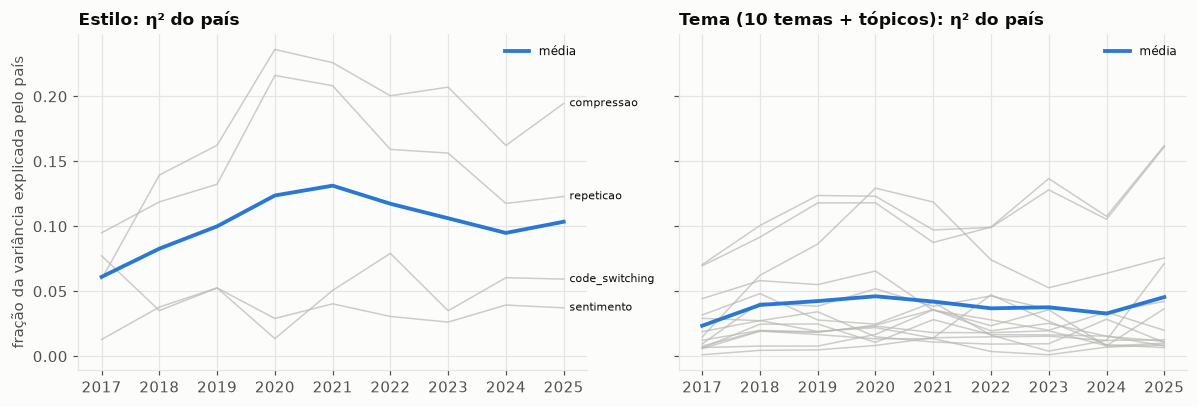

In [14]:
MED_ESTILO = [c for c in ["code_switching", "repeticao", "compressao", "toxicidade", "sentimento"] if c in d]
MED_TEMA = [f"tema_{t}" for t in (TEMAS or [])]
for k in sorted(d["topico"].unique()):
    d[f"top_{k}"] = (d["topico"] == k).astype(float)
MED_TEMA += [f"top_{k}" for k in sorted(d["topico"].unique())]

def eta2(dd, col):
    x = dd[["cc", col]].dropna()
    x = x[x.groupby("cc")[col].transform("size") >= MIN_CEL]
    if x["cc"].nunique() < 3:
        return np.nan
    tot = ((x[col] - x[col].mean()) ** 2).sum()
    entre = (x.groupby("cc")[col].transform("mean") - x[col].mean()).pow(2).sum()
    return entre / tot if tot > 0 else np.nan

def inclinacoes(dd):
    r = {}
    for col in MED_ESTILO + MED_TEMA:
        e = [eta2(g, col) for _, g in dd.groupby("year")]
        r[col] = tendencia(ANOS, e)["inclinacao"]
    return r

obs = inclinacoes(d)
eta_ano = pd.DataFrame({col: [eta2(g, col) for _, g in d.groupby("year")] for col in MED_ESTILO + MED_TEMA}, index=ANOS)
dif_obs = np.nanmean([obs[c] for c in MED_ESTILO]) - np.nanmean([obs[c] for c in MED_TEMA])

def _boot_h3(seed, n):
    r = np.random.default_rng(seed); out = []
    for _ in range(n):
        idx = np.concatenate([r.choice(ix, len(ix)) for ix in d.groupby(["cc", "year"]).indices.values()])
        s = inclinacoes(d.iloc[idx])
        out.append(np.nanmean([s[c] for c in MED_ESTILO]) - np.nanmean([s[c] for c in MED_TEMA]))
    return out
partes = np.array_split(np.arange(N_BOOT_ROB), 8)
difs = np.concatenate(Parallel(n_jobs=8)(delayed(_boot_h3)(SEED + i, len(p)) for i, p in enumerate(partes) if len(p)))
lo, hi = np.percentile(difs, [2.5, 97.5])
tab_h3 = pd.DataFrame({"medida": list(obs), "grupo": ["estilo" if c in MED_ESTILO else "tema" for c in obs],
                       "eta2_medio": [eta_ano[c].mean() for c in obs], "inclinacao_eta2": list(obs.values())})
display(tab_h3.round(5))
print(f"H3: inclinação média do η² (estilo − tema) = {dif_obs:+.5f} | IC95% [{lo:+.5f}, {hi:+.5f}] -> "
      + ("estilo converge mais rápido" if hi < 0 else "tema converge mais rápido" if lo > 0 else "sem diferença clara"))
tab_h3.to_csv(PASTA_RES / "h3_eta2.csv", index=False); eta_ano.to_csv(PASTA_RES / "h3_eta2_por_ano.csv")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, grupo, cols in [(axes[0], "Estilo", MED_ESTILO), (axes[1], "Tema (10 temas + tópicos)", MED_TEMA)]:
    for c in cols:
        ax.plot(ANOS, eta_ano[c], color=COR["neutro"], lw=1, alpha=0.7)
    ax.plot(ANOS, eta_ano[cols].mean(axis=1), color=COR["s1"], lw=2.5, label="média")
    ax.set_title(f"{grupo}: η² do país", loc="left"); ax.legend(fontsize=8)
for c in MED_ESTILO:
    axes[0].text(ANOS[-1] + 0.1, eta_ano[c].iloc[-1], c, fontsize=7, va="center")
axes[0].set_ylabel("fração da variância explicada pelo país")
fig.tight_layout(); fig.savefig(PASTA_RES / "h3_eta2.png"); plt.show()

### Toxicidade: validação e trapificação

A toxicidade é validada contra a flag `explicit` do Spotify (AUC). A **trapificação** usa os tópicos finos com
vocabulário de rap (fração das 10 palavras típicas num léxico de rap): fatia da atenção nesses tópicos por país e
ano, e toxicidade média dentro deles.

In [15]:
if tox is not None:
    _, explicit = datas_lancamento()
    v = estilo[["toxicidade"]].join(explicit.rename("explicit")).dropna()
    v["explicit"] = v["explicit"].astype(str).str.lower().isin(["true", "1"])
    v = v.join(faixas["idioma"])
    print("AUC toxicidade × explicit:", {i: round(roc_auc_score(g["explicit"], g["toxicidade"]), 3)
                                          for i, g in [("todas", v)] + list(v.groupby("idioma")) if g["explicit"].nunique() == 2 and len(g) >= 30})

LEX_RAP = {"bitch", "bitches", "nigga", "niggas", "money", "shit", "fuck", "fucking", "gang", "hoes", "hoe", "drip",
           "ice", "racks", "trap", "glock", "opps", "pussy", "dope", "cash", "bag", "whip", "thug", "hood", "street",
           "streets", "flow", "rap", "rapper", "bro", "homie", "blunt", "weed", "smoke", "lean", "shot", "guns", "gun"}
rap_top = [t for t in set(top_fino) if np.mean([w in LEX_RAP for w, _ in tm.get_topic(t)[:10]]) >= 0.3]
print("tópicos finos de rap:", {t: ", ".join(w for w, _ in tm.get_topic(t)[:6]) for t in rap_top})
d["rap"] = d["topico_fino"].isin(rap_top)
trap = d.groupby(["cc", "year"]).apply(lambda g: pd.Series({"fatia_rap": g.loc[g["rap"], "peso_atencao"].sum(),
       "tox_rap": g.loc[g["rap"], "toxicidade"].mean() if "toxicidade" in g else np.nan})).reset_index()
display((trap.pivot(index="cc", columns="year", values="fatia_rap") * 100).round(0).reindex(PAISES))
linhas = [{"pais": NOMES[cc], **{k: v for k, v in tendencia(g["year"], g["fatia_rap"]).items() if k in ("inclinacao", "p")}}
          for cc, g in trap.groupby("cc")]
display(pd.DataFrame(linhas).round(4))
trap.to_csv(PASTA_RES / "h3_trapificacao.csv", index=False)

tópicos finos de rap: {}


year,2017,2018,2019,2020,2021,2022,2023,2024,2025
cc,,,,,,,,,
us,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
gb,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
ca,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
au,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
de,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
fr,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
br,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
mx,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
jp,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


,pais,inclinacao,p
0,Austrália,0.0,NaN
1,Brasil,0.0,NaN
2,Canadá,0.0,NaN
3,Alemanha,0.0,NaN
4,França,0.0,NaN
5,Reino Unido,0.0,NaN
6,Japão,0.0,NaN
7,México,0.0,NaN
8,EUA,0.0,NaN


## 9. Robustez

Uma variação por vez em relação à especificação principal (H1: estreias domésticas, letra traduzida, repertório,
Wasserstein, BGE-M3, 2018–2025). Para cada variante: inclinação do grupo H1b e do global, com IC bootstrap
(`N_BOOT_ROB` réplicas). Um resultado é robusto se mantém o sinal na maioria das variantes.

In [16]:
oh_top = np.eye(len(set(top_grosso)))[pd.factorize(top_grosso)[0]]
VARIANTES = [
    ("principal", "estreias domésticas", "traduzida", "repertorio", "wasserstein", ()),
    ("todas as músicas", "todas", "traduzida", "repertorio", "wasserstein", ()),
    ("peso = atenção", "estreias domésticas", "traduzida", "atencao", "wasserstein", ()),
    ("letra original", "estreias domésticas", "original", "repertorio", "wasserstein", ()),
    ("original centralizada", "estreias domésticas", "centralizada", "repertorio", "wasserstein", ()),
    ("só estreias", "só estreias", "traduzida", "repertorio", "wasserstein", ()),
    ("só domésticas", "só domésticas", "traduzida", "repertorio", "wasserstein", ()),
    ("sem catálogo", "sem catálogo", "traduzida", "repertorio", "wasserstein", ()),
    ("só exclusivas", "só exclusivas", "traduzida", "repertorio", "wasserstein", ()),
    ("todas, sem 2017", "todas", "traduzida", "repertorio", "wasserstein", (2017,)),
    ("todas, sem 2017–2018", "todas", "traduzida", "repertorio", "wasserstein", (2017, 2018)),
    ("MMD", "estreias domésticas", "traduzida", "repertorio", "mmd", ()),
    ("cosseno entre centroides", "estreias domésticas", "traduzida", "repertorio", "cosseno", ()),
    ("1 − JS sobre tópicos", "estreias domésticas", "topicos", "repertorio", "js_topicos", ()),
]
if "traduzida (LaBSE)" in E:
    VARIANTES.append(("LaBSE", "estreias domésticas", "traduzida (LaBSE)", "repertorio", "wasserstein", ()))
linhas = []
for nome, amostra, versao, peso, met, fora in VARIANTES:
    X = oh_top if versao == "topicos" else E[versao]
    anos = [y for y in ANOS if y not in fora]
    tab, boot = similaridades(AMOSTRAS[amostra], X, met, peso, n_boot=N_BOOT_ROB, anos=anos)
    _, tend = series_grupos(tab, boot, {k: GRUPOS[k] for k in ["H1b: ocidentais, idiomas diferentes", "global", "Japão × outros"]})
    for r in tend.to_dict("records"):
        linhas.append({"variante": nome, **r})
    print(f"ok: {nome}")
rob = pd.DataFrame(linhas)
display(rob.pivot_table(index="variante", columns="grupo", values="leitura", aggfunc="first", sort=False))
rob.to_csv(PASTA_RES / "robustez_hipoteses.csv", index=False)

ok: principal


ok: todas as músicas


ok: peso = atenção


ok: letra original


ok: original centralizada


ok: só estreias


... (7 outputs left out)

/home/besome/Documentos/Coding/socialComp/SocialComp/.venv/lib64/python3.13/site-packages/scipy/spatial/distance.py:1290: RuntimeWarning: invalid value encountered in sqrt
  return np.sqrt(js / 2.0)
/home/besome/Documentos/Coding/socialComp/SocialComp/.venv/lib64/python3.13/site-packages/scipy/spatial/distance.py:1290: RuntimeWarning: invalid value encountered in sqrt
  return np.sqrt(js / 2.0)
/home/besome/Documentos/Coding/socialComp/SocialComp/.venv/lib64/python3.13/site-packages/scipy/spatial/distance.py:1290: RuntimeWarning: invalid value encountered in sqrt
  return np.sqrt(js / 2.0)
/home/besome/Documentos/Coding/socialComp/SocialComp/.venv/lib64/python3.13/site-packages/scipy/spatial/distance.py:1290: RuntimeWarning: invalid value encountered in sqrt
  return np.sqrt(js / 2.0)
/home/besome/Documentos/Coding/socialComp/SocialComp/.venv/lib64/python3.13/site-packages/scipy/spatial/distance.py:1290: RuntimeWarning: invalid value encountered in sqrt
  return np.sqrt(js / 2.0)
/home

ok: 1 − JS sobre tópicos


ok: LaBSE


grupo,"H1b: ocidentais, idiomas diferentes",global,Japão × outros
variante,,,
principal,sem tendência,sem tendência,divergência fraca
todas as músicas,divergência,divergência,divergência
peso = atenção,sem tendência,sem tendência,divergência fraca
letra original,sem tendência,sem tendência,divergência
original centralizada,sem tendência,sem tendência,divergência fraca
só estreias,divergência,divergência,divergência
só domésticas,sem tendência,divergência fraca,sem tendência
sem catálogo,divergência,divergência fraca,divergência fraca
só exclusivas,divergência,divergência,sem tendência


## 10. Resumo

In [17]:
def pega(tend, grupo):
    r = tend[tend["grupo"] == grupo].iloc[0]
    return f"{r['inclinacao']:+.4f}/ano [{r['ic95_lo']:+.4f}, {r['ic95_hi']:+.4f}], p = {r['p']:.3f} -> {r['leitura']}"
t_ed = resultados_h1["estreias domésticas"][3]; t_td = resultados_h1["todas"][3]
fl = tend_forma[tend_forma["cc"].isin(NAO_ANGLO)]
rob_h1 = rob[rob["grupo"] == "H1b: ocidentais, idiomas diferentes"]
m1 = h2[(h2["modelo"] == "M1 distância × tempo")].set_index(["versao", "coef"])
resumo = pd.DataFrame([
    {"hipótese": "H1 forma", "resultado": "; ".join(f"{NOMES[r.cc]} {r.medida}: {r.leitura}" for r in fl.itertuples())},
    {"hipótese": "H1 conteúdo (H1b, estreias domésticas)", "resultado": pega(t_ed, "H1b: ocidentais, idiomas diferentes")},
    {"hipótese": "H1 conteúdo (H1b, todas)", "resultado": pega(t_td, "H1b: ocidentais, idiomas diferentes")},
    {"hipótese": "H1 robustez", "resultado": f"{(rob_h1['inclinacao'] > 0).sum()} de {len(rob_h1)} variantes com inclinação > 0; "
                                             f"{rob_h1['leitura'].str.startswith('convergência').sum()} com convergência"},
    *[{"hipótese": f"H2 ({v}): famílias diferentes", "resultado":
       f"β = {m1.loc[(v, 'familias_dif'), 'beta']:+.4f} (p_QAP = {m1.loc[(v, 'familias_dif'), 'p_qap']:.3f}); "
       f"interação com o tempo β = {m1.loc[(v, 'familias_dif:t'), 'beta']:+.5f} (p_QAP = {m1.loc[(v, 'familias_dif:t'), 'p_qap']:.3f})"}
      for v in ["traduzida", "original"]],
    {"hipótese": "H3", "resultado": f"η² estilo − tema = {dif_obs:+.5f}/ano [{lo:+.5f}, {hi:+.5f}]"},
])
pd.set_option("display.max_colwidth", 200)
display(resumo)
resumo.to_csv(PASTA_RES / "hipoteses_resumo.csv", index=False)

,hipótese,resultado
0,H1 forma,Brasil lingua_local: sobe; Brasil domestico: sobe; Alemanha lingua_local: estável; Alemanha domestico: estável; França lingua_local: sobe; França domestico: sobe; Japão lingua_local: estável; Japã...
1,"H1 conteúdo (H1b, estreias domésticas)","-0.0006/ano [-0.0016, +0.0007], p = 0.399 -> sem tendência"
2,"H1 conteúdo (H1b, todas)","-0.0080/ano [-0.0099, -0.0057], p = 0.004 -> divergência"
3,H1 robustez,5 de 15 variantes com inclinação > 0; 2 com convergência
4,H2 (traduzida): famílias diferentes,β = -0.1826 (p_QAP = 0.001); interação com o tempo β = -0.01125 (p_QAP = 0.000)
5,H2 (original): famílias diferentes,β = -0.2130 (p_QAP = 0.000); interação com o tempo β = -0.01267 (p_QAP = 0.000)
6,H3,"η² estilo − tema = +0.00271/ano [-0.00147, +0.00545]"
